# Bitcoin Price Prediction with an RNN

We predict the next-day Bitcoin closing price using a basic vanilla RNN.
We resample to **daily** closes, choose the epoch budget with walk-forward time-series CV, then scale up to the full series.

In [18]:
import time
import gc

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler

DEVICE = torch.device('mps' if torch.mps.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

Using device: mps


## 1. Load data

In [19]:
path = kagglehub.dataset_download('jkraak/bitcoin-price-dataset')
df = pd.read_csv(path + '/bitcoin_2017_to_2023.csv')

df['date'] = pd.to_datetime(df['timestamp'], unit='ms')
daily = (
    df.set_index('date')['close']
    .resample('D')
    .last()
    .dropna()
)

print(f'Raw rows: {len(df):,}  |  Daily points: {len(daily):,}')
print(f'Range: {daily.index[0].date()} → {daily.index[-1].date()}')
daily.tail()

Raw rows: 3,126,000  |  Daily points: 2,176
Range: 2017-08-17 → 2023-08-01


date
2023-07-28    29314.14
2023-07-29    29352.90
2023-07-30    29281.09
2023-07-31    29232.25
2023-08-01    28902.49
Freq: D, Name: close, dtype: float64

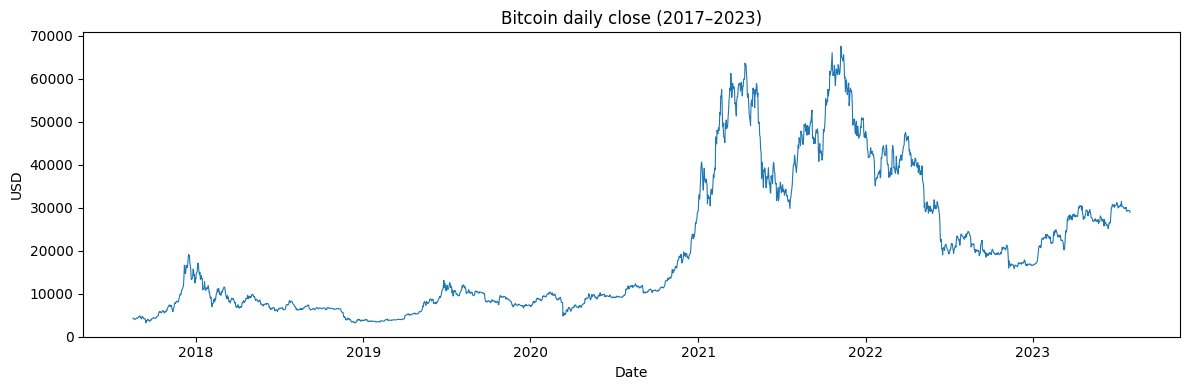

In [20]:
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily.values, linewidth=0.8)
plt.title('Bitcoin daily close (2017–2023)')
plt.xlabel('Date')
plt.ylabel('USD')
plt.tight_layout()
plt.show()

## 2. RNN model and helpers

In [21]:
class BitcoinRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1):
        super().__init__()
        self.rnn = nn.RNN(
            input_size, hidden_size, num_layers,
            batch_first=True, nonlinearity='tanh',
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


def make_sequences(prices, seq_len=30):
    arr = np.asarray(prices, dtype=np.float32)
    if len(arr) <= seq_len:
        raise ValueError(f'Need more than {seq_len} points, got {len(arr)}')
    X = np.stack([arr[i : i + seq_len] for i in range(len(arr) - seq_len)])
    y = arr[seq_len:]
    return X[:, :, None], y


def prepare_data(prices, seq_len=30, train_frac=0.8):
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(np.asarray(prices, dtype=np.float64).reshape(-1, 1)).flatten()
    X, y = make_sequences(scaled, seq_len)
    split = int(len(X) * train_frac)
    tensors = {
        'X_train': torch.tensor(X[:split], device=DEVICE),
        'y_train': torch.tensor(y[:split], device=DEVICE).unsqueeze(1),
        'X_test': torch.tensor(X[split:], device=DEVICE),
        'y_test': torch.tensor(y[split:], device=DEVICE).unsqueeze(1),
    }
    return tensors, scaler


def train_model(
    tensors,
    epochs=50,
    lr=1e-3,
    hidden_size=64,
    num_layers=1,
    verbose=True,
    X_val=None,
    y_val=None,
):
    model = BitcoinRNN(hidden_size=hidden_size, num_layers=num_layers).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = {'train': [], 'val': []}

    has_val = X_val is not None
    if has_val:
        X_v = torch.tensor(X_val, device=DEVICE)
        y_v = torch.tensor(y_val, device=DEVICE).unsqueeze(1)

    best_state = None
    best_val = float('inf')
    best_epoch = epochs

    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        loss = loss_fn(model(tensors['X_train']), tensors['y_train'])
        opt.zero_grad()
        loss.backward()
        opt.step()
        history['train'].append(loss.item())

        if has_val:
            model.eval()
            with torch.no_grad():
                v = float(loss_fn(model(X_v), y_v))
            history['val'].append(v)
            if v < best_val:
                best_val = v
                best_epoch = epoch
                best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}

        if verbose and (epoch == 1 or epoch % 10 == 0 or epoch == epochs):
            msg = f'  epoch {epoch:3d}/{epochs}  train MSE: {loss.item():.6f}'
            if has_val:
                msg += f'  val MSE: {history["val"][-1]:.6f}'
            print(msg)

    if best_state is not None:
        model.load_state_dict(best_state)
        model.to(DEVICE)

    elapsed = time.time() - t0
    model.eval()
    with torch.no_grad():
        test_pred = model(tensors['X_test']).cpu().numpy()
        test_true = tensors['y_test'].cpu().numpy()
        test_mse = float(np.mean((test_pred - test_true) ** 2))

    return model, history, test_mse, elapsed, best_epoch


def inverse_scale(scaler, values):
    return scaler.inverse_transform(np.asarray(values).reshape(-1, 1)).flatten()


def time_series_cv_best_epoch(
    prices,
    seq_len=30,
    n_splits=4,
    max_epochs=100,
    hidden_size=64,
    lr=1e-3,
    min_train_frac=0.5,
):
    prices = np.asarray(prices, dtype=np.float64)
    n = len(prices)
    min_train = max(int(n * min_train_frac), seq_len + 90)
    remaining = n - min_train
    fold_size = remaining // n_splits

    fold_val_curves = []
    fold_norm_curves = []
    fold_best_epochs = []
    fold_stats = []

    print(f'Walk-forward CV: {n_splits} folds, max_epochs={max_epochs}')
    print(f'  min_train_rows={min_train} ({min_train} days), fold_size={fold_size} ({fold_size} days)')

    for fold in range(n_splits):
        train_end = min_train + fold * fold_size
        val_end = n if fold == n_splits - 1 else train_end + fold_size

        scaler = MinMaxScaler()
        tr = scaler.fit_transform(prices[:train_end].reshape(-1, 1)).flatten()
        va = scaler.transform(prices[train_end:val_end].reshape(-1, 1)).flatten()

        X_tr, y_tr = make_sequences(tr, seq_len)

        tv = np.concatenate([tr, va])
        X_va, y_va = [], []
        for t in range(train_end, val_end):
            if t < seq_len:
                continue
            X_va.append(tv[t - seq_len : t])
            y_va.append(tv[t])
        X_va = np.asarray(X_va, dtype=np.float32)[:, :, None]
        y_va = np.asarray(y_va, dtype=np.float32)

        if len(X_tr) < 10 or len(X_va) < 10:
            print(f'  fold {fold + 1}: skipped')
            continue

        tensors = {
            'X_train': torch.tensor(X_tr, device=DEVICE),
            'y_train': torch.tensor(y_tr, device=DEVICE).unsqueeze(1),
            'X_test': torch.tensor(X_va, device=DEVICE),
            'y_test': torch.tensor(y_va, device=DEVICE).unsqueeze(1),
        }

        model, hist, _, _, best_ep = train_model(
            tensors,
            epochs=max_epochs,
            lr=lr,
            hidden_size=hidden_size,
            verbose=False,
            X_val=X_va,
            y_val=y_va,
        )

        val_curve = np.asarray(hist['val'], dtype=np.float64)
        norm_curve = val_curve / max(val_curve[0], 1e-8)

        model.eval()
        with torch.no_grad():
            preds_s = model(tensors['X_test']).cpu().numpy().flatten()
        preds = inverse_scale(scaler, preds_s)
        true = inverse_scale(scaler, y_va)
        mae = float(np.mean(np.abs(preds - true)))
        rmse = float(np.sqrt(np.mean((preds - true) ** 2)))

        fold_val_curves.append(val_curve)
        fold_norm_curves.append(norm_curve)
        fold_best_epochs.append(best_ep)
        fold_stats.append({
            'fold': fold + 1,
            'train_rows': train_end,
            'val_rows': val_end - train_end,
            'best_epoch': best_ep,
            'best_val_mse_scaled': float(val_curve.min()),
            'mae_usd': mae,
            'rmse_usd': rmse,
        })

        print(
            f'  fold {fold + 1}/{n_splits}: '
            f'train={train_end}d, val={val_end - train_end}d, '
            f'best_epoch={best_ep}, '
            f'val_MSE_scaled={val_curve.min():.4f}, '
            f'MAE=${mae:,.0f}, RMSE=${rmse:,.0f}'
        )

    norm_mean = np.mean(np.stack(fold_norm_curves, axis=0), axis=0)
    epoch_from_norm_mean = int(np.argmin(norm_mean) + 1)
    epoch_from_median = int(np.median(fold_best_epochs))
    best_epoch = epoch_from_median

    print(
        f'\nEpoch from normalized-mean curve: {epoch_from_norm_mean}'
        f'\nEpoch from median of fold bests:  {epoch_from_median}'
    )

    return (
        best_epoch,
        norm_mean,
        fold_best_epochs,
        fold_val_curves,
        fold_norm_curves,
        fold_stats,
        epoch_from_norm_mean,
    )


## 3. Time-series CV → choose best epoch

Expanding-window walk-forward CV on the daily series (past → future only), with a large shared train prefix (~50%).
Scalers are fit inside each fold. We report MAE/RMSE in USD, normalize val curves for diagnostics, and set `BEST_EPOCHS` to the **median** of fold-wise best epochs.

Walk-forward CV: 4 folds, max_epochs=100
  min_train_rows=1088 (1088 days), fold_size=272 (272 days)
  fold 1/4: train=1088d, val=272d, best_epoch=100, val_MSE_scaled=0.8801, MAE=$10,092, RMSE=$14,929
  fold 2/4: train=1360d, val=272d, best_epoch=74, val_MSE_scaled=0.0021, MAE=$2,203, RMSE=$2,762
  fold 3/4: train=1632d, val=272d, best_epoch=63, val_MSE_scaled=0.0006, MAE=$1,167, RMSE=$1,627
  fold 4/4: train=1904d, val=272d, best_epoch=60, val_MSE_scaled=0.0002, MAE=$756, RMSE=$1,010

Epoch from normalized-mean curve: 100
Epoch from median of fold bests:  68

Per-fold summary (USD):
 fold  train_rows  val_rows  best_epoch      mae_usd     rmse_usd  best_val_mse_scaled
    1        1088       272         100 10092.154297 14928.950195             0.880075
    2        1360       272          74  2203.424316  2761.776123             0.002092
    3        1632       272          63  1167.145386  1626.849854             0.000639
    4        1904       272          60   756.210266  1010.06

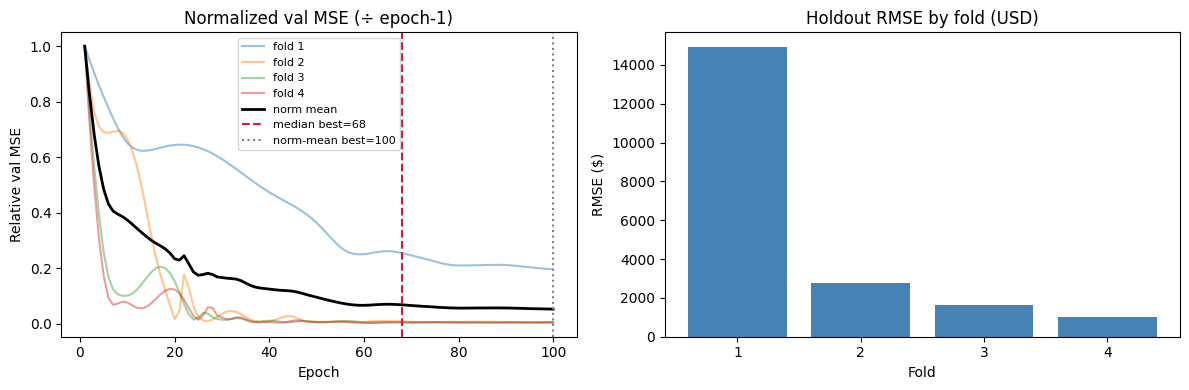

In [22]:
SEQ_LEN = 30
MAX_EPOCHS = 100
N_SPLITS = 4

(
    BEST_EPOCHS,
    norm_mean_curve,
    fold_best_epochs,
    fold_val_curves,
    fold_norm_curves,
    fold_stats,
    epoch_from_norm_mean,
) = time_series_cv_best_epoch(
    daily.values,
    seq_len=SEQ_LEN,
    n_splits=N_SPLITS,
    max_epochs=MAX_EPOCHS,
    min_train_frac=0.5,
)

fold_stats_df = pd.DataFrame(fold_stats)
print('\nPer-fold summary (USD):')
print(
    fold_stats_df[
        ['fold', 'train_rows', 'val_rows', 'best_epoch', 'mae_usd', 'rmse_usd', 'best_val_mse_scaled']
    ].to_string(index=False)
)
print(
    f'\nSelected BEST_EPOCHS = {BEST_EPOCHS}  '
    f'(fold bests={fold_best_epochs}, normalized-mean argmin={epoch_from_norm_mean})'
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, curve in enumerate(fold_norm_curves):
    axes[0].plot(range(1, len(curve) + 1), curve, alpha=0.45, label=f'fold {i + 1}')
axes[0].plot(
    range(1, len(norm_mean_curve) + 1),
    norm_mean_curve,
    color='black',
    linewidth=2,
    label='norm mean',
)
axes[0].axvline(BEST_EPOCHS, color='crimson', linestyle='--', label=f'median best={BEST_EPOCHS}')
axes[0].axvline(
    epoch_from_norm_mean, color='gray', linestyle=':', label=f'norm-mean best={epoch_from_norm_mean}'
)
axes[0].set_title('Normalized val MSE (÷ epoch-1)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Relative val MSE')
axes[0].legend(fontsize=8)

axes[1].bar(fold_stats_df['fold'].astype(str), fold_stats_df['rmse_usd'], color='steelblue')
axes[1].set_title('Holdout RMSE by fold (USD)')
axes[1].set_xlabel('Fold')
axes[1].set_ylabel('RMSE ($)')
plt.tight_layout()
plt.show()


## 4. Short period — 90 days

Last 90 daily closes, 30-day look-back, chronological **80/20** train/test.
Trains for `BEST_EPOCHS` from time-series CV.

Training sequences: 48  |  Test sequences: 12  |  epochs: 68
  epoch   1/68  train MSE: 0.440783
  epoch  10/68  train MSE: 0.082393
  epoch  20/68  train MSE: 0.066110
  epoch  30/68  train MSE: 0.055492
  epoch  40/68  train MSE: 0.038761
  epoch  50/68  train MSE: 0.021630
  epoch  60/68  train MSE: 0.018447
  epoch  68/68  train MSE: 0.015157
Test MSE (scaled): 0.001918  |  Training time: 0.72s


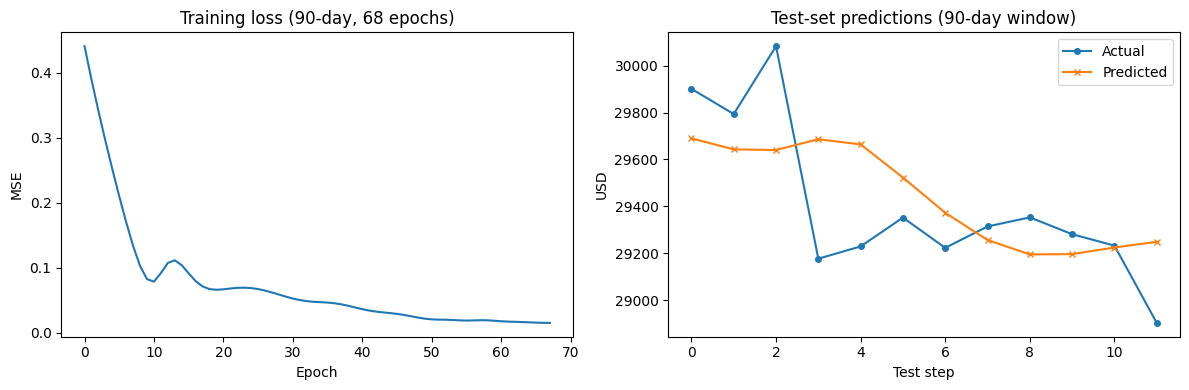

Test RMSE: $277.04


In [24]:
SHORT_DAYS = 90

short_prices = daily.values[-SHORT_DAYS:]
tensors, scaler = prepare_data(short_prices, seq_len=SEQ_LEN)

print(
    f'Training sequences: {len(tensors["X_train"])}  |  '
    f'Test sequences: {len(tensors["X_test"])}  |  epochs: {BEST_EPOCHS}'
)

model_short, hist_short, test_mse_short, time_short, _ = train_model(
    tensors, epochs=BEST_EPOCHS
)
print(f'Test MSE (scaled): {test_mse_short:.6f}  |  Training time: {time_short:.2f}s')

model_short.eval()
with torch.no_grad():
    preds_scaled = model_short(tensors['X_test']).cpu().numpy().flatten()
    true_scaled = tensors['y_test'].cpu().numpy().flatten()

preds = inverse_scale(scaler, preds_scaled)
true = inverse_scale(scaler, true_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_short['train'])
axes[0].set_title(f'Training loss (90-day, {BEST_EPOCHS} epochs)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')

axes[1].plot(true, label='Actual', marker='o', markersize=4)
axes[1].plot(preds, label='Predicted', marker='x', markersize=4)
axes[1].set_title('Test-set predictions (90-day window)')
axes[1].set_xlabel('Test step')
axes[1].set_ylabel('USD')
axes[1].legend()
plt.tight_layout()
plt.show()

rmse_usd = np.sqrt(np.mean((preds - true) ** 2))
print(f'Test RMSE: ${rmse_usd:,.2f}')


## 5. Scaling up — how long a period can we train on?

Progressively increase the number of daily points and measure training time, memory, and test error.
Each run uses the same architecture and `BEST_EPOCHS`.


--- 90 days ---
  sequences=60, epochs=68, time=0.74s, RMSE=$274, mem=179MB

--- 180 days ---
  sequences=150, epochs=68, time=0.77s, RMSE=$1,018, mem=404MB

--- 365 days ---
  sequences=335, epochs=68, time=0.70s, RMSE=$843, mem=408MB

--- 730 days ---
  sequences=700, epochs=68, time=0.70s, RMSE=$959, mem=412MB

--- 1095 days ---
  sequences=1065, epochs=68, time=0.71s, RMSE=$1,107, mem=415MB

--- 1460 days ---
  sequences=1430, epochs=68, time=0.77s, RMSE=$1,204, mem=415MB

--- 1800 days ---
  sequences=1770, epochs=68, time=0.77s, RMSE=$1,173, mem=420MB

--- 2176 days (full) ---
  sequences=2146, epochs=68, time=1.08s, RMSE=$1,189, mem=359MB
   days  sequences  epochs  train_time_s  test_mse_scaled  test_rmse_usd  \
0    90         60      68          0.74         0.001870     273.540009   
1   180        150      68          0.77         0.008109    1017.869995   
2   365        335      68          0.70         0.002892     842.780029   
3   730        700      68          0.70 

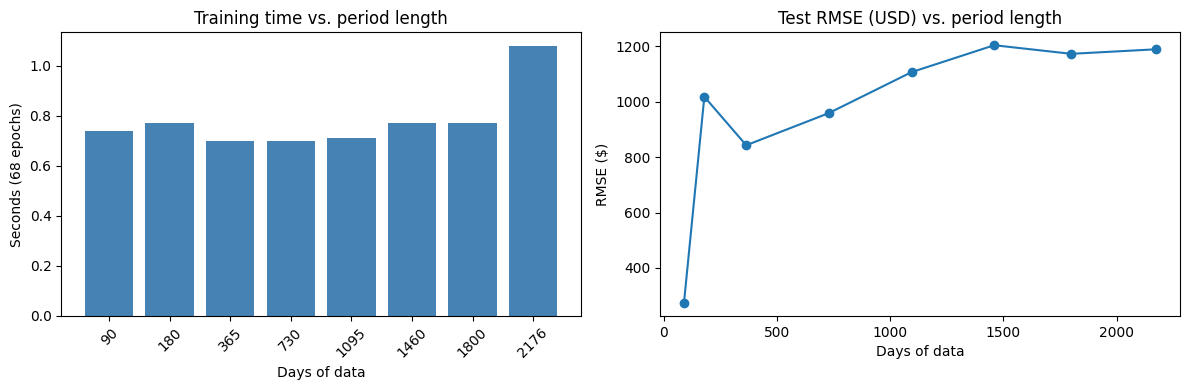

In [25]:
import psutil

PERIODS = [90, 180, 365, 730, 1095, 1460, 1800, len(daily)]
results = []

for n_days in PERIODS:
    label = f'{n_days} days' if n_days < len(daily) else f'{n_days} days (full)'
    print(f'\n--- {label} ---')
    try:
        prices = daily.values[-n_days:]
        tensors, scaler = prepare_data(prices, seq_len=SEQ_LEN)

        model, hist, test_mse, elapsed, _ = train_model(
            tensors, epochs=BEST_EPOCHS, verbose=False
        )

        mem_after = psutil.Process().memory_info().rss / 1e6
        n_seq = len(tensors['X_train']) + len(tensors['X_test'])

        with torch.no_grad():
            preds_s = model(tensors['X_test']).cpu().numpy().flatten()
            true_s = tensors['y_test'].cpu().numpy().flatten()
        rmse = np.sqrt(
            np.mean((inverse_scale(scaler, preds_s) - inverse_scale(scaler, true_s)) ** 2)
        )

        results.append({
            'days': n_days,
            'sequences': n_seq,
            'epochs': BEST_EPOCHS,
            'train_time_s': round(elapsed, 2),
            'test_mse_scaled': round(test_mse, 6),
            'test_rmse_usd': round(rmse, 2),
            'mem_mb': round(mem_after, 0),
            'status': 'OK',
        })
        print(
            f'  sequences={n_seq}, epochs={BEST_EPOCHS}, '
            f'time={elapsed:.2f}s, RMSE=${rmse:,.0f}, mem={mem_after:.0f}MB'
        )

        del model, tensors, scaler
        gc.collect()
    except Exception as exc:
        results.append({'days': n_days, 'status': f'FAILED: {exc}'})
        print(f'  FAILED: {exc}')
        break

results_df = pd.DataFrame(results)
print(results_df)

ok = results_df[results_df['status'] == 'OK']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(ok['days'].astype(str), ok['train_time_s'], color='steelblue')
axes[0].set_title('Training time vs. period length')
axes[0].set_xlabel('Days of data')
axes[0].set_ylabel(f'Seconds ({BEST_EPOCHS} epochs)')
axes[0].tick_params(axis='x', rotation=45)

axes[1].plot(ok['days'], ok['test_rmse_usd'], 'o-')
axes[1].set_title('Test RMSE (USD) vs. period length')
axes[1].set_xlabel('Days of data')
axes[1].set_ylabel('RMSE ($)')
plt.tight_layout()
plt.show()


It can be clearly seen that the RMSE increases drastically after 150 days of data, suggesting a vanishing gradient problem.

## 6. Full-dataset model

Train on all available daily data with `BEST_EPOCHS`, then plot the held-out test tail.

Full dataset: 2176 days — 1716 train / 430 test sequences | epochs: 68
  epoch   1/68  train MSE: 0.188986
  epoch  10/68  train MSE: 0.056036
  epoch  20/68  train MSE: 0.036409
  epoch  30/68  train MSE: 0.009391
  epoch  40/68  train MSE: 0.000644
  epoch  50/68  train MSE: 0.001543
  epoch  60/68  train MSE: 0.000996
  epoch  68/68  train MSE: 0.000654
Test MSE (scaled): 0.000353  |  Training time: 1.13s


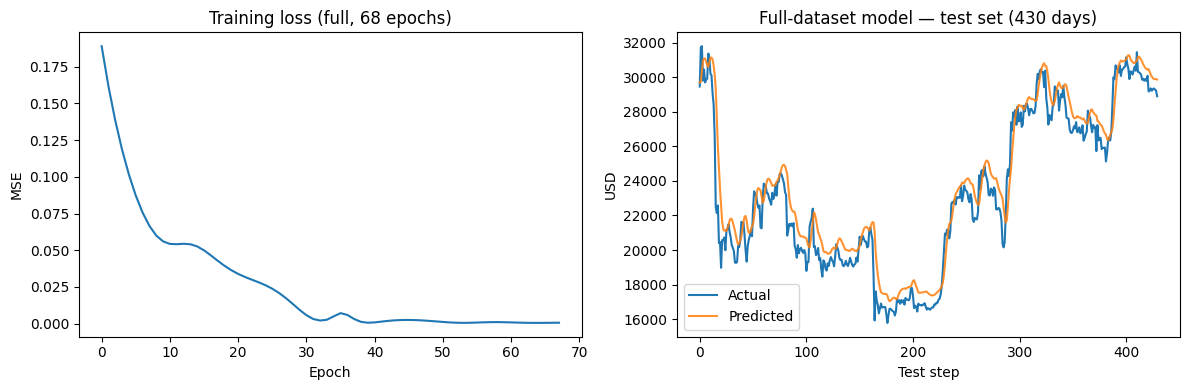

Full-model test RMSE: $1,209.46


In [26]:
full_prices = daily.values
tensors_full, scaler_full = prepare_data(full_prices, seq_len=SEQ_LEN)

print(
    f'Full dataset: {len(full_prices)} days — '
    f'{len(tensors_full["X_train"])} train / {len(tensors_full["X_test"])} test sequences '
    f'| epochs: {BEST_EPOCHS}'
)

model_full, hist_full, test_mse_full, time_full, _ = train_model(
    tensors_full, epochs=BEST_EPOCHS
)
print(f'Test MSE (scaled): {test_mse_full:.6f}  |  Training time: {time_full:.2f}s')

model_full.eval()
with torch.no_grad():
    preds_s = model_full(tensors_full['X_test']).cpu().numpy().flatten()
    true_s = tensors_full['y_test'].cpu().numpy().flatten()

preds_full = inverse_scale(scaler_full, preds_s)
true_full = inverse_scale(scaler_full, true_s)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_full['train'])
axes[0].set_title(f'Training loss (full, {BEST_EPOCHS} epochs)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')

axes[1].plot(true_full, label='Actual', linewidth=1.5)
axes[1].plot(preds_full, label='Predicted', linewidth=1.5, alpha=0.85)
axes[1].set_title(f'Full-dataset model — test set ({len(true_full)} days)')
axes[1].set_xlabel('Test step')
axes[1].set_ylabel('USD')
axes[1].legend()
plt.tight_layout()
plt.show()

rmse_full = np.sqrt(np.mean((preds_full - true_full) ** 2))
print(f'Full-model test RMSE: ${rmse_full:,.2f}')


## 7. Conclusion

**Epoch selection:** walk-forward CV with a large train prefix; `BEST_EPOCHS` is the median of fold-wise best epochs. Fold scaled MSE can differ with market regimes — compare folds via USD RMSE/MAE.

**Daily data:** the vanilla RNN (64 hidden, tanh) trains on the full daily series (~2,176 days) quickly on this machine.

**Minute-level data:** ~3.1M rows would need batching and much more memory; daily resampling is the practical trade-off here.

**Takeaway:** CV-chosen epochs plus daily closes keep training honest and tractable; prediction quality is limited more by non-stationarity than by compute.